<a href="https://colab.research.google.com/github/igornvidal/apollo_analytics_academy/blob/main/An%C3%A1lise_Iris.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Importando o Dataset Iris

In [ ]:
import pandas as pd
from sklearn.datasets import load_iris

# Carrega os dados do Iris
iris = load_iris()

# Cria um DataFrame do Pandas
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)

# Adiciona a coluna com a classe/alvo correspondente
df['target'] = iris.target

# Mapeia os números das classes para os nomes reais das espécies
df['species'] = df['target'].map({i: name for i, name in enumerate(iris.target_names)})

# Exibe as primeiras linhas do DataFrame
display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


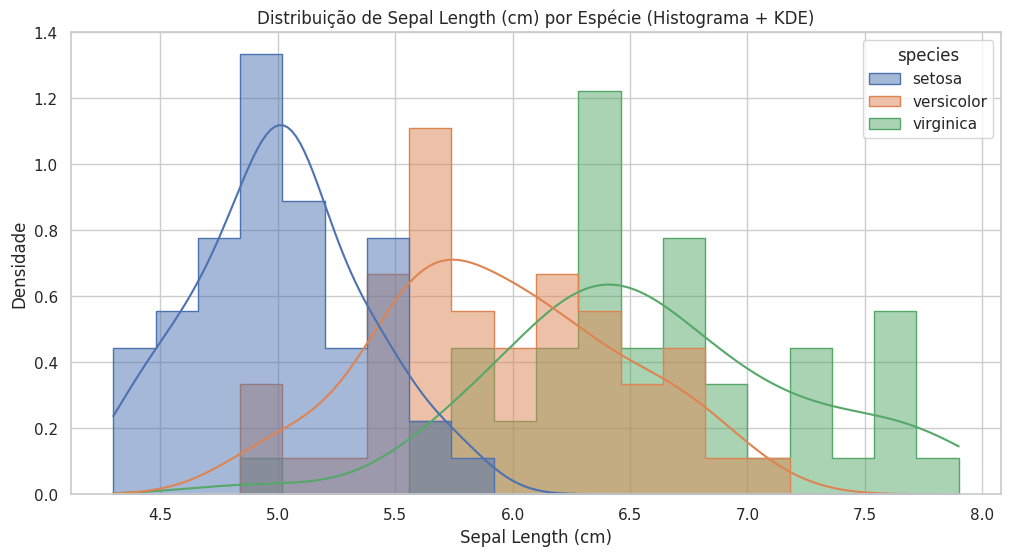

=== Intervalos de Confiança (95%) para a Média ===
Setosa: Médio = 5.006 | IC 95% = [4.906, 5.106]
Versicolor: Médio = 5.936 | IC 95% = [5.789, 6.083]
Virginica: Médio = 6.588 | IC 95% = [6.407, 6.769]


=== Teste ANOVA de Uma Via ===
Estatística F: 119.2645
Valor p: 1.6697e-31
Resultado: Há diferença estatisticamente significativa entre as médias (p < 0.05).

=== Teste de Comparação Múltipla (Tukey HSD) ===
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1     group2   meandiff p-adj lower  upper  reject
---------------------------------------------------------
    setosa versicolor     0.93   0.0 0.6862 1.1738   True
    setosa  virginica    1.582   0.0 1.3382 1.8258   True
versicolor  virginica    0.652   0.0 0.4082 0.8958   True
---------------------------------------------------------


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy.stats as stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# 1. Configurando o estilo dos gráficos
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# 2. Histograma e KDE comparando 'sepal length (cm)' por espécie
sns.histplot(data=df, x='sepal length (cm)', hue='species', kde=True, element='step', stat='density', common_norm=False, alpha=0.5, bins = 20)
plt.title('Distribuição de Sepal Length (cm) por Espécie (Histograma + KDE)')
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Densidade')
plt.show()

# 3. Cálculo de Intervalos de Confiança (95%) para a média de cada espécie
print("=== Intervalos de Confiança (95%) para a Média ===")
species_groups = {}
for species in df['species'].unique():
    data = df[df['species'] == species]['sepal length (cm)']
    species_groups[species] = data

    mean = np.mean(data)
    sem = stats.sem(data)  # Erro padrão da média
    ci = stats.t.interval(0.95, df=len(data)-1, loc=mean, scale=sem)

    print(f"{species.capitalize()}: Médio = {mean:.3f} | IC 95% = [{ci[0]:.3f}, {ci[1]:.3f}]")

print("\n" + "="*50 + "\n")

# 4. Teste de ANOVA para verificar se há diferença significativa geral
f_val, p_val = stats.f_oneway(species_groups['setosa'], species_groups['versicolor'], species_groups['virginica'])
print("=== Teste ANOVA de Uma Via ===")
print(f"Estatística F: {f_val:.4f}")
print(f"Valor p: {p_val:.4e}")

if p_val < 0.05:
    print("Resultado: Há diferença estatisticamente significativa entre as médias (p < 0.05).")
    print("\n=== Teste de Comparação Múltipla (Tukey HSD) ===")
    # Teste de Tukey para identificar quais pares são significativamente diferentes
    tukey = pairwise_tukeyhsd(endog=df['sepal length (cm)'],
                              groups=df['species'],
                              alpha=0.05)
    print(tukey)
else:
    print("Resultado: Não há evidências de diferença estatisticamente significativa entre as médias (p >= 0.05).")